# LiverCare AI – Liver Disease Classification Using Logistic Regression

## Project Overview
LiverCare AI is a machine learning project that uses Logistic Regression to classify whether a person is likely to belong to the liver disease patient group or the non-liver disease patient group based on medical attributes.
The project focuses on understanding binary classification, probability-based prediction, sigmoid function, decision thresholds, feature scaling, class weights, and model evaluation.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    log_loss,
    confusion_matrix,
    classification_report
)

Dataset name: Indian Liver Patient Dataset.
Dataset source: https://archive.ics.uci.edu/dataset/225/ilpd+indian+liver+patient+dataset
Target: Dataset.
Class 1: Liver patient.
Class 0: Non-liver patient.
Number of rows and columns, taken from your actual df.shape output.
Description of the ten input features.


## Data Understanding and Exploration

In [30]:
df = pd.read_csv(r"C:\Users\dell\Desktop\mitali\indian_liver_patient.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


Duplicate Records: 13

Target Class Counts:
Dataset
1    416
2    167
Name: count, dtype: int64

Target Class Percentages:
Dataset
1    71.36
2    28.64
Name: proportion, dtype: float64


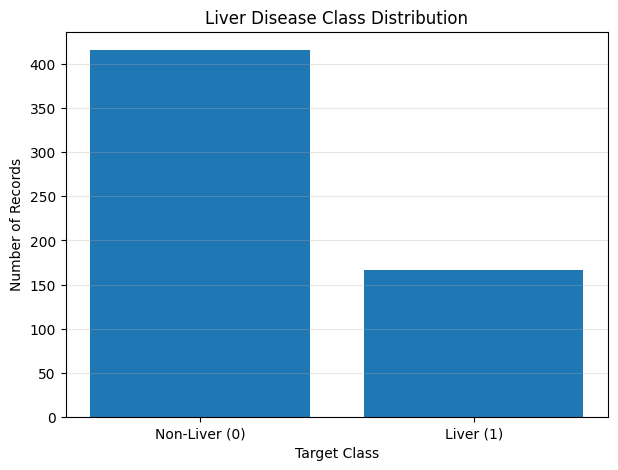

In [31]:
print("Duplicate Records:", df.duplicated().sum())


print("\nTarget Class Counts:")
print(df["Dataset"].value_counts().sort_index())

print("\nTarget Class Percentages:")
print((df["Dataset"].value_counts(normalize=True) * 100).round(2))


class_counts = df["Dataset"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Non-Liver (0)", "Liver (1)"],
    class_counts.values
)

plt.title("Liver Disease Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")
plt.grid(axis="y", alpha=0.3)
plt.show()

### Data Quality and Class Distribution

Duplicate records and target class counts were checked to understand the quality of the dataset.
The bar chart shows the distribution of liver and non-liver patient records. This helps identify whether the dataset is balanced or imbalanced.
Class imbalance is important because a model may perform well on the majority class while failing to identify the minority class.

In [32]:
print("Column Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Column Names:
Index(['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin',
       'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
       'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin',
       'Albumin_and_Globulin_Ratio', 'Dataset'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                  

In [33]:
df["Gender"] = df["Gender"].map({
    "Male": 1,
    "Female": 0
})


df["Dataset"] = df["Dataset"].map({
    1: 1,
    2: 0
})

X = df.drop("Dataset", axis=1)
y = df["Dataset"]

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Features:
   Age  Gender  Total_Bilirubin  Direct_Bilirubin  Alkaline_Phosphotase  \
0   65       0              0.7               0.1                   187   
1   62       1             10.9               5.5                   699   
2   62       1              7.3               4.1                   490   
3   58       1              1.0               0.4                   182   
4   72       1              3.9               2.0                   195   

   Alamine_Aminotransferase  Aspartate_Aminotransferase  Total_Protiens  \
0                        16                          18             6.8   
1                        64                         100             7.5   
2                        60                          68             7.0   
3                        14                          20             6.8   
4                        27                          59             7.3   

   Albumin  Albumin_and_Globulin_Ratio  
0      3.3                        0.90  


### Feature Preparation

The target column `Dataset` is separated from the independent variables.
Gender is converted into numerical form:
- Male = 1
- Female = 0

The target variable is converted into two classes:
- 1 = Liver patient
- 0 = Non-liver patient

The identifier-like target column is not used as an input feature.
The remaining medical attributes are used as independent variables for Logistic Regression.


## Splitting the Dataset

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (466, 10)
Testing data: (117, 10)


In [35]:
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())

print("\nTraining Class Percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Class Percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training Records: 466
Testing Records: 117

Training Data Shape: (466, 10)
Testing Data Shape: (117, 10)

Training Class Distribution:
Dataset
0    133
1    333
Name: count, dtype: int64

Testing Class Distribution:
Dataset
0    34
1    83
Name: count, dtype: int64

Training Class Percentages:
Dataset
1    71.46
0    28.54
Name: proportion, dtype: float64

Testing Class Percentages:
Dataset
1    70.94
0    29.06
Name: proportion, dtype: float64


In [36]:

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Preprocessing will be handled by the Pipeline.")


Training data: (466, 10)
Testing data: (117, 10)
Preprocessing will be handled by the Pipeline.


## Why Logistic Regression?

Linear Regression is mainly used to predict continuous numerical values. It can produce values below 0 or above 1, which are not suitable as probabilities.

Our problem has two possible classes:
- 0 = Non-Liver
- 1 = Liver

Therefore, Logistic Regression is suitable because it estimates the probability of belonging to the positive class.

### Sigmoid Function

The sigmoid function converts a numerical score into a probability between 0 and 1.

\[
P(y=1)=\frac{1}{1+e^{-z}}
\]

A decision threshold is used to convert the probability into a class label.
For example:
- Probability greater than or equal to 0.5 → Class 1.
- Probability below 0.5 → Class 0.

In [37]:
##  Understanding the Sigmoid Function

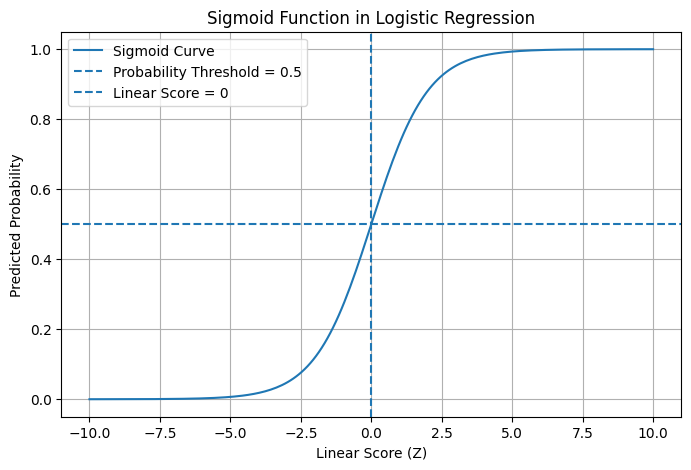

In [38]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 200)

probability = sigmoid(z)

plt.figure(figsize=(8, 5))

plt.plot(z, probability, label="Sigmoid Curve")

plt.axhline(
    0.5,
    linestyle="--",
    label="Probability Threshold = 0.5"
)

plt.axvline(
    0,
    linestyle="--",
    label="Linear Score = 0"
)

plt.xlabel("Linear Score (Z)")
plt.ylabel("Predicted Probability")
plt.title("Sigmoid Function in Logistic Regression")

plt.legend()
plt.grid()
plt.show()

In [39]:
##  Building the Logistic Regression Model

## Logistic Regression Model Settings

The Logistic Regression model is trained using the following settings:

- Maximum iterations: 1000
- Class weight: None for the normal model
- Regularization parameter C: 1.0
- Missing values: Median imputation
- Feature scaling: StandardScaler

A Pipeline is used to combine preprocessing and model training.

The imputer and scaler are fitted only on training data to prevent data leakage.

In [40]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


model = Pipeline([

    
    ("imputer", SimpleImputer(strategy="median")),

    
    ("scaler", StandardScaler()),

    # Logistic Regression
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        C=1.0
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Model Intercept: 1.5555275236408892


,Feature,Coefficient
5,Alamine_Aminotransferase,1.070912
6,Aspartate_Aminotransferase,0.793735
3,Direct_Bilirubin,0.646038
8,Albumin,-0.607941
7,Total_Protiens,0.499200
0,Age,0.324470
4,Alkaline_Phosphotase,0.290907
2,Total_Bilirubin,0.265208
9,Albumin_and_Globulin_Ratio,0.198851
1,Gender,0.079150


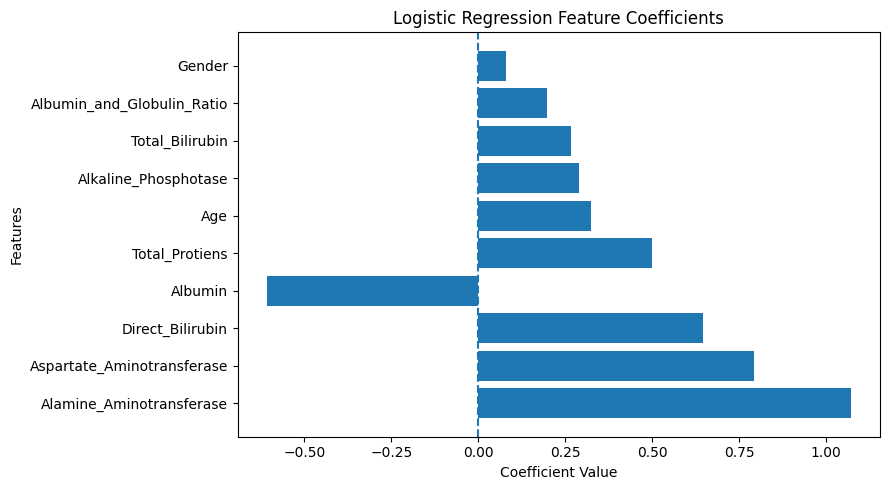

In [41]:
# Extract Logistic Regression estimator
logistic_model = model.named_steps["classifier"]

# Display intercept
print("Model Intercept:", logistic_model.intercept_[0])

# Display coefficients
coefficient_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
})

coefficient_df = coefficient_df.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

display(coefficient_df)

# Plot coefficients
plt.figure(figsize=(9, 5))

plt.barh(
    coefficient_df["Feature"],
    coefficient_df["Coefficient"]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.title("Logistic Regression Feature Coefficients")

plt.tight_layout()
plt.show()

### Coefficient Interpretation

Logistic Regression assigns a coefficient to each independent feature.

- A positive coefficient indicates that an increase in the feature is associated with an increase in the log-odds of the positive class, keeping other features constant.
- A negative coefficient indicates a decrease in the log-odds of the positive class.
- The intercept represents the model's baseline log-odds when all scaled features are zero.

These coefficients describe learned associations and do not establish medical causation.

In [42]:

y_probability = model.predict_proba(X_test)[:, 1]


threshold = 0.5

y_pred = (y_probability >= threshold).astype(int)

print("Predictions completed!")

Predictions completed!


In [43]:
prediction_df = pd.DataFrame({
    "Actual Class": y_test.to_numpy(),
    "Predicted Probability": y_probability,
    "Predicted Class": y_pred
})

print("Sample Test Predictions:")

display(prediction_df.head(10))

Sample Test Predictions:


,Actual Class,Predicted Probability,Predicted Class
0,1,0.842421,1
1,1,0.718508,1
2,0,0.731389,1
3,1,0.863386,1
4,1,0.730967,1
5,1,0.665975,1
6,0,0.677992,1
7,0,0.738518,1
8,1,0.770277,1
9,0,0.542423,1


In [44]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nLog Loss:", log_loss(y_test, y_probability))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Liver", "Liver"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Accuracy: 0.7350427350427351

Log Loss: 0.4530072750563693

Classification Report:
              precision    recall  f1-score   support

   Non-Liver       0.67      0.18      0.28        34
       Liver       0.74      0.96      0.84        83

    accuracy                           0.74       117
   macro avg       0.70      0.57      0.56       117
weighted avg       0.72      0.74      0.68       117


Confusion Matrix:
[[ 6 28]
 [ 3 80]]


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_test, y_probability)

# Display confusion matrix values
print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

# Create evaluation table
metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1-Score",
        "ROC-AUC"
    ],

    "Formula": [
        "(TP + TN) / Total",
        "TP / (TP + FP)",
        "TP / (TP + FN)",
        "TN / (TN + FP)",
        "2 * P * R / (P + R)",
        "Area under ROC curve"
    ],

    "Result": [
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        roc_auc
    ]
})

display(metrics_df.round(4))

True Negative (TN): 6
False Positive (FP): 28
False Negative (FN): 3
True Positive (TP): 80


,Metric,Formula,Result
0,Accuracy,(TP + TN) / Total,0.7350
1,Precision,TP / (TP + FP),0.7407
2,Recall,TP / (TP + FN),0.9639
3,Specificity,TN / (TN + FP),0.1765
4,F1-Score,2 * P * R / (P + R),0.8377
5,ROC-AUC,Area under ROC curve,0.8303


### Confusion Matrix Interpretation

- True Positive (TP): A liver patient correctly predicted as a liver patient.
- True Negative (TN): A non-liver patient correctly predicted as a non-liver patient.
- False Positive (FP): A non-liver patient incorrectly predicted as a liver patient.
- False Negative (FN): A liver patient incorrectly predicted as a non-liver patient.

For a health-screening demonstration, false negatives are important because they represent positive cases missed by the model. False positives are also important because they may cause unnecessary follow-up tests.

Therefore, accuracy alone is not sufficient to evaluate this model.

In [46]:
from sklearn.dummy import DummyClassifier

# Majority-class baseline model
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(
    X_train,
    y_train
)

baseline_pred = baseline_model.predict(X_test)

# Baseline accuracy
baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

print("MAJORITY CLASS BASELINE")

print("Baseline Accuracy:", round(baseline_accuracy, 4))

print("\nBaseline Classification Report:")

print(classification_report(
    y_test,
    baseline_pred,
    labels=[0, 1],
    target_names=["Non-Liver", "Liver"],
    zero_division=0
))

# Compare baseline and logistic regression
baseline_comparison = pd.DataFrame({
    "Model": [
        "Majority Class Baseline",
        "Normal Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        accuracy_score(y_test, y_pred)
    ],
    "Precision": [
        precision_score(y_test, baseline_pred, zero_division=0),
        precision_score(y_test, y_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, baseline_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, baseline_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

display(baseline_comparison.round(4))

MAJORITY CLASS BASELINE
Baseline Accuracy: 0.7094

Baseline Classification Report:
              precision    recall  f1-score   support

   Non-Liver       0.00      0.00      0.00        34
       Liver       0.71      1.00      0.83        83

    accuracy                           0.71       117
   macro avg       0.35      0.50      0.41       117
weighted avg       0.50      0.71      0.59       117



,Model,Accuracy,Precision,Recall,F1-Score
0,Majority Class Baseline,0.7094,0.7094,1.0000,0.8300
1,Normal Logistic Regression,0.7350,0.7407,0.9639,0.8377


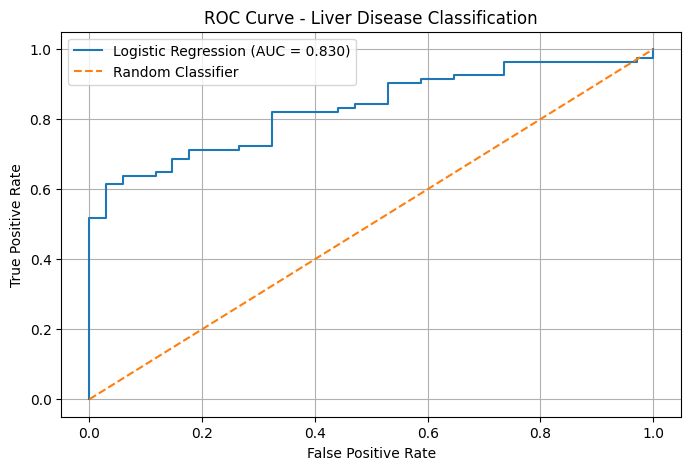

ROC-AUC Score: 0.8303


In [47]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    y_probability
)

auc_value = roc_auc_score(
    y_test,
    y_probability
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_value:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Liver Disease Classification")

plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", round(auc_value, 4))

### ROC-AUC Interpretation

The ROC curve shows the relationship between the True Positive Rate and False Positive Rate at different classification thresholds.

ROC-AUC measures the model's ability to rank a randomly selected positive record above a randomly selected negative record.

- 1.0 indicates perfect ranking.
- 0.5 indicates performance similar to random ranking.

A higher ROC-AUC generally indicates better class-ranking ability, but it does not guarantee that predictions at a particular threshold are suitable for the intended use.

In [48]:
balanced_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        C=1.0
    ))
])

balanced_model.fit(X_train, y_train)


balanced_probability = balanced_model.predict_proba(X_test)[:, 1]

balanced_pred = (balanced_probability >= 0.5).astype(int)


print("BALANCED LOGISTIC REGRESSION")

print("\nAccuracy:")
print(accuracy_score(y_test, balanced_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    balanced_pred,
    target_names=["Non-Liver", "Liver"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, balanced_pred, labels=[0, 1]))

BALANCED LOGISTIC REGRESSION

Accuracy:
0.7350427350427351

Classification Report:
              precision    recall  f1-score   support

   Non-Liver       0.53      0.85      0.65        34
       Liver       0.92      0.69      0.79        83

    accuracy                           0.74       117
   macro avg       0.72      0.77      0.72       117
weighted avg       0.81      0.74      0.75       117


Confusion Matrix:
[[29  5]
 [26 57]]


In [49]:
thresholds = [0.3, 0.5, 0.7]

threshold_results = []

for threshold in thresholds:

    predictions = (
        balanced_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,

        "Predicted Positive": int(predictions.sum()),

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),

        "Specificity": (
            tn / (tn + fp) if (tn + fp) > 0 else 0
        ),

        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Predicted Positive,Accuracy,Precision,Recall,Specificity,F1-Score
0,0.3,103,0.7436,0.7573,0.9398,0.2647,0.8387
1,0.5,62,0.7350,0.9194,0.6867,0.8529,0.7862
2,0.7,38,0.6154,1.0000,0.4578,1.0000,0.6281


### Threshold Comparison Interpretation

A threshold determines the minimum probability required to classify a record as positive.

A lower threshold generally predicts more positive cases, which may improve recall but can increase false positives.

A higher threshold generally predicts fewer positive cases, which may improve precision but can increase false negatives.

The final threshold should be selected based on the evaluation results and the relative cost of each type of error, rather than accuracy alone.


## Confusion Matrix

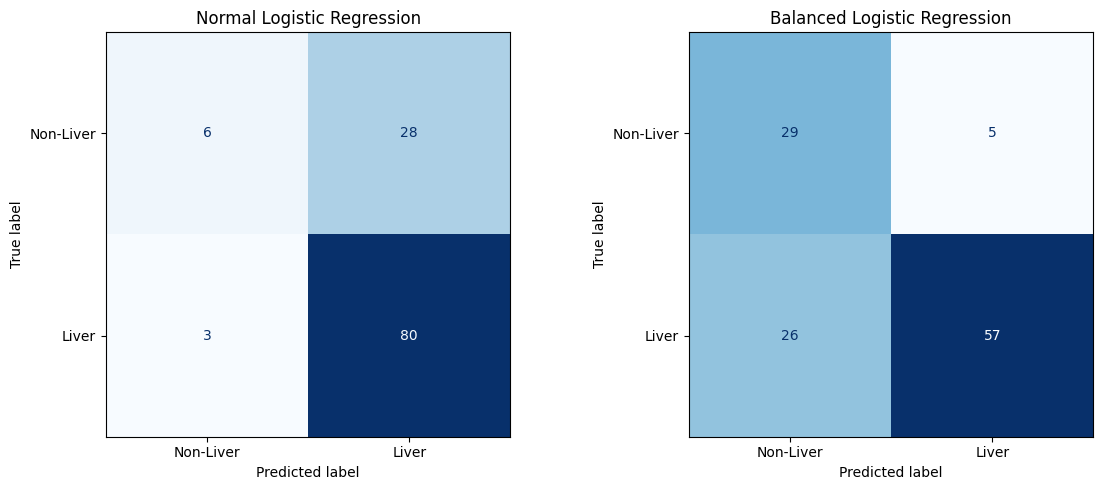

In [50]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm_normal = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
)

cm_balanced = confusion_matrix(
    y_test, balanced_pred, labels=[0, 1]
)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))


disp1 = ConfusionMatrixDisplay(
    confusion_matrix=cm_normal,
    display_labels=["Non-Liver", "Liver"]
)

disp1.plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title("Normal Logistic Regression")

disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["Non-Liver", "Liver"]
)

disp2.plot(
    ax=axes[1],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[1].set_title("Balanced Logistic Regression")

plt.tight_layout()
plt.show()


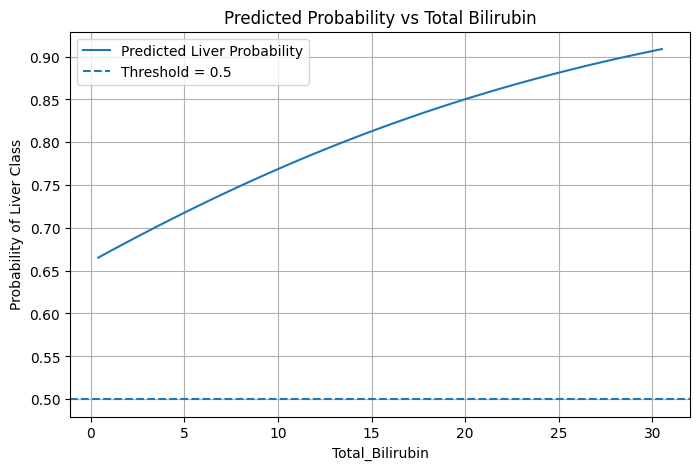

In [51]:
feature_name = "Total_Bilirubin"

# Generate values within the observed feature range
feature_range = np.linspace(
    X_train[feature_name].min(),
    X_train[feature_name].max(),
    100
)

# Keep other features at training medians
plot_data = pd.DataFrame(
    [X_train.median()] * len(feature_range),
    columns=X_train.columns
)

plot_data[feature_name] = feature_range

# Predict probability
plot_probabilities = model.predict_proba(
    plot_data
)[:, 1]

plt.figure(figsize=(8, 5))

plt.plot(
    feature_range,
    plot_probabilities,
    label="Predicted Liver Probability"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="Threshold = 0.5"
)

plt.xlabel(feature_name)
plt.ylabel("Probability of Liver Class")
plt.title("Predicted Probability vs Total Bilirubin")

plt.legend()
plt.grid()
plt.show()

### Decision Behaviour Interpretation

The graph shows how the predicted probability of the liver class changes as Total Bilirubin changes while all other features are held at their training median values.

The horizontal reference line represents the default decision threshold of 0.5.

This visualization helps explain how Logistic Regression changes its probability estimate based on an input feature. It does not prove that the feature directly causes liver disease.

In [52]:
# Create one illustrative new record
new_record = pd.DataFrame([{
    "Age": 45,
    "Gender": 1,
    "Total_Bilirubin": 1.0,
    "Direct_Bilirubin": 0.3,
    "Alkaline_Phosphotase": 200,
    "Alamine_Aminotransferase": 25,
    "Aspartate_Aminotransferase": 30,
    "Total_Protiens": 7.0,
    "Albumin": 3.5,
    "Albumin_and_Globulin_Ratio": 1.0
}])

# Use your selected threshold here after deciding it
recommended_threshold = 0.5

new_probability = model.predict_proba(
    new_record
)[0, 1]

new_class = int(
    new_probability >= recommended_threshold
)

print("Predicted Probability:", round(new_probability, 4))

print("Predicted Class:", new_class)

if new_class == 1:
    print("Model Output: Liver patient class")
else:
    print("Model Output: Non-liver patient class")

Predicted Probability: 0.6324
Predicted Class: 1
Model Output: Liver patient class


In [53]:
# Training and testing predictions
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

performance_comparison = pd.DataFrame({
    "Dataset": ["Training", "Testing"],

    "Accuracy": [
        accuracy_score(y_train, train_pred),
        accuracy_score(y_test, test_pred)
    ],

    "Precision": [
        precision_score(y_train, train_pred, zero_division=0),
        precision_score(y_test, test_pred, zero_division=0)
    ],

    "Recall": [
        recall_score(y_train, train_pred, zero_division=0),
        recall_score(y_test, test_pred, zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_train, train_pred, zero_division=0),
        f1_score(y_test, test_pred, zero_division=0)
    ]
})

display(performance_comparison.round(4))

,Dataset,Accuracy,Precision,Recall,F1-Score
0,Training,0.7339,0.7506,0.9399,0.8347
1,Testing,0.7350,0.7407,0.9639,0.8377


### Training and Testing Performance

Training metrics show how well the model performs on data used to fit it.

Testing metrics show how well it performs on unseen data.

A large difference between training and testing performance may indicate overfitting. If both performances are poor, the model may be underfitting or the available features may not be sufficiently informative.

Testing performance is more important when estimating how the model may perform on new records.

# Results and Conclusion

The project implemented Logistic Regression to classify liver and non-liver patient records using the Indian Liver Patient Dataset.

### Models Implemented
1. Normal Logistic Regression
2. Class-Balanced Logistic Regression
3. Majority-Class Baseline

### Data Preparation
- Gender was converted into numerical values.
- The target variable was converted into binary classes.
- Missing numerical values were handled using median imputation.
- StandardScaler was used for feature scaling.
- Stratified train-test splitting was performed.

### Model Evaluation
The models were evaluated using:
- Accuracy
- Precision
- Recall
- Specificity
- F1-score
- ROC-AUC
- Confusion Matrix

Thresholds of 0.3, 0.5 and 0.7 were compared to understand how changing the decision threshold affects the classification results.

### Final Observations

Insert the actual test-set results from the notebook here. Explain which model performed better and why, particularly in terms of identifying the liver-positive class.

### Limitations
- The dataset contains a limited number of records.
- The model may not generalize to every population.
- Predictions depend on the quality and distribution of the input data.
- A predicted probability is not a guaranteed medical outcome.

### Conclusion

This project demonstrates how Logistic Regression can be applied to binary classification. It also highlights the importance of data preprocessing, probability prediction, class imbalance, confusion matrix analysis, and threshold selection.

The model is an academic demonstration and must not be used as an independent medical diagnostic system.
